In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models #type:ignore
import matplotlib.pyplot as plt

In [18]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize the data - as numbers are from 0 to 255, we divide by 255 to get values between 0 and 1
x_train, x_test = x_train / 255.0, x_test / 255.0


In [19]:
# VAE (Variational Autoencoder)
# Flattening in previous step would give 28x28 = 784 elements

x_train = x_train.reshape(len(x_train), 784)
x_test = x_test.reshape(len(x_test), 784)
encoding_dim = 32
input_img = layers.Input(shape=(784,))
encoded = layers.Dense(encoding_dim, activation='relu')(input_img)
decoded = layers.Dense(784, activation='sigmoid')(encoded)
model = models.Model(input_img, decoded)


In [20]:
# Compile the model

model.compile(optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

# Train the model
#model.fit(x_train, y_train, epochs=2)
model.fit(x_train,y_train, epochs=50, batch_size=256, shuffle=True, validation_data=(x_test, y_test))


Epoch 1/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6872 - loss: 1.6163 - val_accuracy: 0.8790 - val_loss: 0.4777
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8932 - loss: 0.3945 - val_accuracy: 0.9104 - val_loss: 0.3252
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9115 - loss: 0.3139 - val_accuracy: 0.9164 - val_loss: 0.2885
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9184 - loss: 0.2854 - val_accuracy: 0.9227 - val_loss: 0.2707
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9228 - loss: 0.2674 - val_accuracy: 0.9233 - val_loss: 0.2600
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9269 - loss: 0.2521 - val_accuracy: 0.9276 - val_loss: 0.2480
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9319 - loss: 0.2385 - val_accuracy: 0.9306 - val_loss: 0.2337
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9352 - loss: 0.2263 - val_accuracy: 0.

In [21]:
# Evaluate the model
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc}")



313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9632 - loss: 0.1254
Test accuracy: 0.9631999731063843


In [22]:
# Make predictions
predictions = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


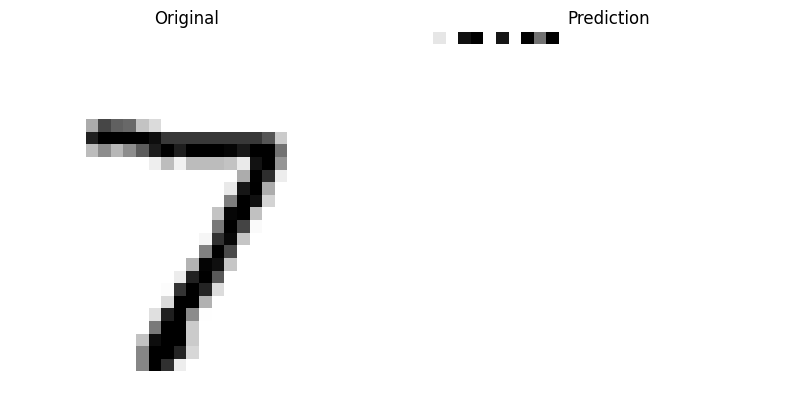

In [23]:
# Display the first image and prediction

plt.figure(figsize=(10, 5))

# Left Plot: Original Image
plt.subplot(1, 2, 1)
plt.title("Original")  # Optional: adds a label to the plot
plt.imshow(x_test[0].reshape(28, 28), cmap=plt.cm.binary)
plt.axis('off')        # Optional: removes the pixel axis numbers

# Right Plot: Predicted/Decoded Image
plt.subplot(1, 2, 2)
plt.title("Prediction")  # Optional: adds a label to the plot
plt.imshow(predictions[0].reshape(28, 28), cmap=plt.cm.binary)
plt.axis('off')        # Optional: removes the pixel axis numbers
plt.show()